#Algebra Lineal: vectores, matrices como transformaciones, determinante y sistemas lineales.

## Ejercicio 1: Producto punto, norma y ángulo entre vectores
Calculo el producto punto con `np.dot` y `@`, la norma de cada vector y el ángulo que forman.

In [1]:
import numpy as np
u = np.array([1,0])
v = np.array([3,0])
p1 = np.dot(u,v)
p2 = u @ v
if p1 == p2:
    print("np.dot y @ dan el mismo resultado:", p1)
#Normas
norma_u = np.linalg.norm(u)
norma_v = np.linalg.norm(v)
angulo = np.degrees(np.arccos((p1)/(norma_u*norma_v)))
print("El angulo es de: ",round(angulo,2))

np.dot y @ dan el mismo resultado: 3
El angulo es de:  0.0


**Conclusión:** El producto punto entre dos vectores se puede calcular con `np.dot(u, v)` o con `u @ v`, y ambos dan el mismo resultado. Con `np.linalg.norm` obtuve la longitud (norma) de cada vector. Con el producto punto y las normas calculé el ángulo entre ellos usando la fórmula cos(θ) = (u·v) / (‖u‖ ‖v‖), y comprobé que vectores en la misma dirección dan 0°.

## Ejercicio 2: Matrices como transformaciones (rotación y escala)
Aplico una rotación de 45° y una escala a un círculo de puntos 2D, y comparo el antes y el después.


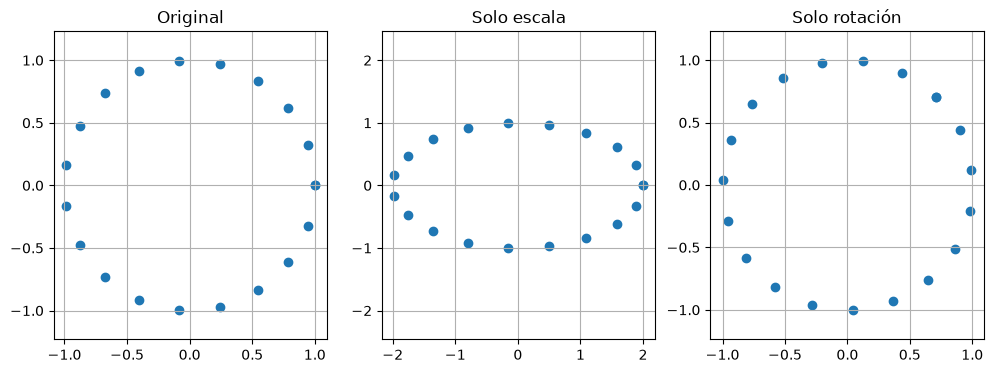

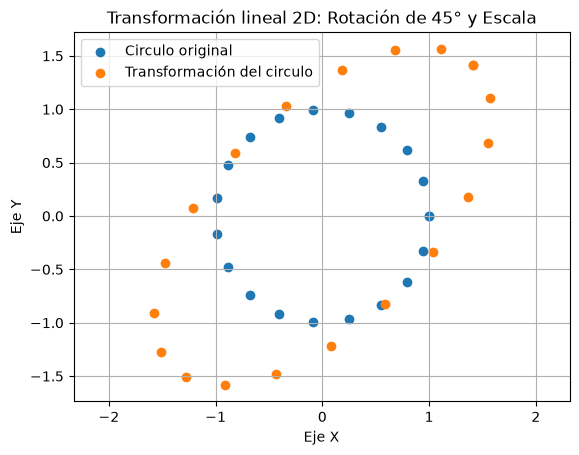

In [2]:
import matplotlib.pyplot as plt
t = np.linspace(0,2*np.pi,20)
puntos = np.array([np.cos(t), np.sin(t)])
#Rotación
a=np.radians(45)
R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
#Matriz escala
S = np.array([[2,0],[0,1]])
puntos_transformados = R @ S @ puntos

solo_R = R @ puntos
solo_S = S @ puntos

plt.figure(figsize=(12, 4))
for i, (pts, nombre) in enumerate([(puntos, "Original"), (solo_S, "Solo escala"), (solo_R, "Solo rotación")]):
    plt.subplot(1, 3, i + 1)
    plt.scatter(pts[0], pts[1])
    plt.title(nombre)
    plt.grid()
    plt.axis("equal")
plt.show()

plt.figure()
plt.scatter(puntos[0], puntos[1], label="Circulo original")
plt.scatter(puntos_transformados[0], puntos_transformados[1], label="Transformación del circulo")
plt.grid()
plt.title("Transformación lineal 2D: Rotación de 45° y Escala")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend()
plt.axis("equal")
plt.show()

**Conclusión:** Generé 20 puntos en forma de círculo y les apliqué dos transformaciones lineales: una rotación de 45° (matriz R, con el ángulo convertido a radianes) y una escala (matriz S = [[2,0],[0,1]]) que duplica el eje x. Las grafiqué por separado y también combinadas (R @ S @ puntos, donde primero actúa S y luego R), y las comparé con el círculo original. Observé que la rotación solo mueve los puntos y conserva la forma circular, mientras que la escala deforma el círculo en una elipse. Esto muestra que una matriz 2×2 transforma todo el plano: las columnas indican a dónde caen los vectores base î y ĵ.

## Ejercicio 3: Composición de transformaciones y el orden del producto
Compruebo que `R @ S` y `S @ R` dan resultados distintos: el orden en que se aplican importa.

In [3]:
#Permutación
A = R @ S
B = S @ R
print(A)
print(B)
print("Es permutable la multiplicación: ",np.allclose(A, B)) 

[[ 1.41421356 -0.70710678]
 [ 1.41421356  0.70710678]]
[[ 1.41421356 -1.41421356]
 [ 0.70710678  0.70710678]]
Es permutable la multiplicación:  False


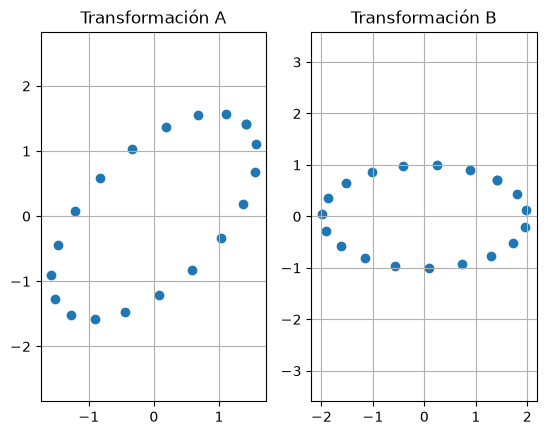

In [4]:
TA = A@puntos
TB = B@puntos
for i, (pts, nombre) in enumerate([(TA, "Transformación A"), (TB, "Transformación B")]):
    plt.subplot(1, 2, i + 1)
    plt.scatter(pts[0], pts[1])
    plt.title(nombre)
    plt.grid()
    plt.axis("equal")
plt.show()


**Conclusión:** Calculé A = R @ S y B = S @ R, y obtuve matrices distintas (`np.allclose(A, B)` dio `False`). Al graficar los puntos transformados, A produjo una elipse inclinada a 45° y B una elipse horizontal. Esto muestra que el producto de matrices no es conmutativo: en `A @ B` primero se aplica B y luego A. En A, primero se estira el círculo y luego se gira esa elipse. En B, primero se gira el círculo (que sigue siendo un círculo) y luego se estira.

## Ejercicio 4: Determinante como cambio de área
Interpreto el determinante de la rotación, la escala y una matriz singular.

In [5]:
#Determinantes
print(np.linalg.det(R)) # = 1: la rotación no cambia el área. El círculo gira, pero conserva su tamaño.
print(np.linalg.det(S)) # = 2: la escala duplica el área, porque estira el eje x al doble y deja el eje y igual.
print(np.linalg.det(np.array([[1, 2], [2, 4]]))) # = 0: las columnas son linealmente dependientes, así que el plano se aplasta sobre una línea, que tiene área 0. Por ende la matriz NO tiene inversa.

1.0
2.0
0.0


**Conclusión:** Calculé el determinante de tres matrices: la rotación R (det = 1), la escala S (det = 2) y la matriz [[1,2],[2,4]] (det = 0). El determinante indica por cuánto se multiplica el área al aplicar la transformación. La rotación conserva el área, la escala la duplica, y en la tercera las columnas son linealmente dependientes (la segunda es el doble de la primera), por lo que el plano se aplasta sobre una línea de área 0. Un determinante de 0 significa que la matriz no tiene inversa.

## Ejercicio 5: Inversa y sistemas de ecuaciones lineales
Resuelvo `A x = b` con `solve` e `inv`, verifico la solución y veo qué pasa con una matriz sin inversa.

In [6]:
A = np.array([[2, 1], [1, 3]])
b = np.array([1, 2])

#Confirmación de si A tiene inversa, debe de ser diferente de 0
print(np.linalg.det(A)) 


x1 = np.linalg.solve(A, b)
x2 = np.linalg.inv(A) @ b
print(x1, x2, np.allclose(x1, x2))
# solve resuelve A x = b directamente (con una factorización LU), sin calcular la inversa.
# inv(A) @ b da el mismo resultado, pero es más lento y acumula más error de redondeo.
# En la práctica se usa solve.
print(A @ x1) # Comprobación: debe devolver b = [1, 2]

try:
    np.linalg.inv(np.array([[1, 2], [2, 4]]))
except np.linalg.LinAlgError as e:
    print("Error esperado:", e)
#Da LinAlgError: su determinante es 0, así que no existe la inversa.



5.000000000000001
[0.2 0.6] [0.2 0.6] True
[1. 2.]
Error esperado: Singular matrix


**Conclusión:** Resolví el sistema A x = b con `np.linalg.solve` y con `np.linalg.inv(A) @ b`, y ambos dieron la misma solución, x = [0.2, 0.6] (`np.allclose` dio `True`). Verifiqué que A @ x devuelve b. El determinante de A es 5 (distinto de 0), por lo que tiene inversa. En cambio, con la matriz singular [[1,2],[2,4]] (det = 0), `np.linalg.inv` lanzó un `LinAlgError`, porque no existe su inversa. Usé `solve` porque resuelve el sistema directamente, sin calcular la inversa, y es más rápido y numéricamente más estable.